# 04. Baseline model

## ***1. Konfiguracja środowiska***

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, Model
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import joblib

import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))
from src.utils import *
from src.image_pipeline import *

I0000 00:00:1795020052.887008     880 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795020052.927670     880 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795020054.071722     880 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
print(f"Wersja tensorflow: {tf.__version__}")
print(f"Liczba wykrytych GPU: {len(tf.config.list_physical_devices('GPU'))}")
print(f"Zidentyfikowana karta graficzna: {tf.config.list_physical_devices('GPU')[0]}")

Wersja tensorflow: 2.21.0
Liczba wykrytych GPU: 1
Zidentyfikowana karta graficzna: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


W0000 00:00:1794928812.055211   26916 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


### 1.1. Zmienne globalne

In [3]:
IMG_SIZE=(224,224)
BATCH_SIZE=32
SEED = 42
tf.keras.utils.set_random_seed(SEED)

label_encoder = joblib.load("../dataset/label_encoder.joblib")
class_names = label_encoder.classes_
print(class_names)

['akiec' 'bcc' 'bkl' 'df' 'mel' 'nv' 'vasc']


## ***2. Wczytanie przygotowanych danych***

Dalsza praca odbywać się będzie z użyciem przetransformowanych, przygotowanych w poprzednich etapach danych.

In [4]:
train_df = pd.read_csv('../dataset/train_processed.csv')
val_df = pd.read_csv('../dataset/val_processed.csv')
test_df = pd.read_csv('../dataset/test_processed.csv')

print(f"Train: {len(train_df)} próbek")
print(f"Validation: {len(val_df)} próbek")
print(f"Test: {len(test_df)} próbek")

assert not train_df.empty
assert not val_df.empty
assert not test_df.empty

Train: 6409 próbek
Validation: 1602 próbek
Test: 2004 próbek


## ***3. Przygotowanie pipeline'u tf.data***

Pierwsza implementacja modelu wspomagania diagnostyki zmian skórnych opierać się będzie modelem konwolucyjnym, trenowanym wyłącznie na obrazach dermatoskopowych. Z tego powodu dane są mapowane na obiekty `tf.data.Dataset` o strukturze ([zdjęcia], [diagnoza OneHot]), za pomocą funkcji 'create_dataset' zdefiniowanej w pliku `../src/utils.py'. Dataset jest podzielony na porcje po 32 elementów, co jest standardowym punktem startowym przy treningu modeli. Obrazy zostały przeskalowane także do wybranej wartości.

In [5]:
train = create_dataset(train_df, training=True, BATCH_SIZE=BATCH_SIZE, IMG_SIZE=IMG_SIZE)
val = create_dataset(val_df, BATCH_SIZE=BATCH_SIZE, IMG_SIZE=IMG_SIZE)
test = create_dataset(test_df, BATCH_SIZE=BATCH_SIZE, IMG_SIZE=IMG_SIZE)

W0000 00:00:1794928813.007247   26916 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794928813.159452   26916 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13209 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a


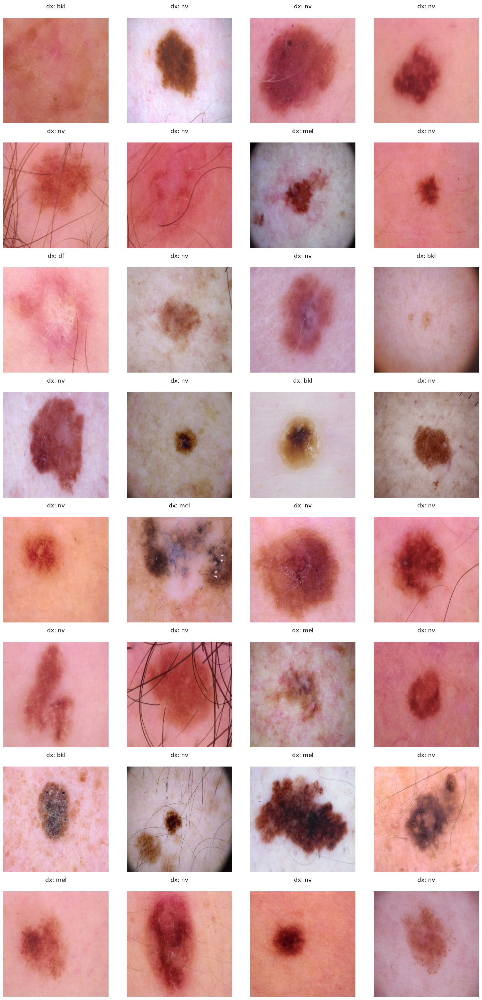

In [6]:
sample_batch = next(train.as_numpy_iterator())
fig, axes = plt.subplots(8,4, figsize=(15, 30))
row, col = 0,0

for sample, label in zip(*sample_batch):
    if col != 0 and col % 4 == 0:
        col=0
        row+=1
    ax = axes[row, col]
    ax.imshow(sample.astype('uint8'))
    ax.set_title(f"dx: {class_names[np.argmax(label)]}\n")
    ax.axis('off')
    col += 1

plt.tight_layout()
plt.show()

## ***4. Model bazowy EfficientNet-B0***

Model bazowy będzie opierać się na architekturze EfficientNet, jako że ta osiągnęła najwyższe wyniki w literaturze w tematyce systemów klasyfikacji zmian skórnych. Wykorzystany zostanie konkretnie model B0, jako że posiada on stosunkowo niewiele parametrów (5.3 mln), co czyni go potencjalnie dobrym kandydatem do implementacji w aplikacji webowej.  

EfficientNet-B0 przyjmuje na wejściu obrazy o rozmiarze 224 x 224 piksele (stąd wybór IMG_SIZE) zakodowane w przestrzeni RGB - oba te warunki zostały spełnione dla naszych danych za pośrednictwem funkcji `create_dataset()`.

Wagi modelu bazowego zostaną zamrożone, a wytrenowana zostanie jedynie jego głowica klasyfikująca. W dodatku zostaną zbadane trzy warianty modelu - bez augmentacji danych, z lekką oraz z silną augmentacją danych. Spośród nich zostanie wybrany baseline.

Efektywność modelu zostanie oceniona za pomocą metryki $F1_{macro}$, by obiektywnie ocenić model, który uczy się na niezbalansowanych danych. Jako że implementacja F1_macro w bibliotece Keras wymaga, by etykiety były zakodowane jako OneHot, wewnątrz `create_dataset` znajduje się ich przekodowanie z ustalonego wcześniej integer encoding.

### F1 Macro

$$
F1_{\text{macro}} = \frac{1}{K} \sum_{i=1}^{K} F1_i
$$

### F1 dla klasy $i$

$$
F1_i = 2 \cdot \frac{Precision_i \cdot Recall_i}{Precision_i + Recall_i}
$$

### Precision

$$
Precision_i = \frac{TP_i}{TP_i + FP_i}
$$

### Recall

$$
Recall_i = \frac{TP_i}{TP_i + FN_i}
$$


In [ ]:
def build_base_model(augmentation=None):
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
    )
    
    base_model.trainable = False

    inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    x = inputs


    if augmentation is not None:
        x = augmentation()(x)
    
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    
    outputs = layers.Dense(7, activation="softmax")(x)
    
    model = Model(inputs, outputs)

    return model

In [8]:
def build_confusion_matrix(model, dataset = val):
    y_pred = model.predict(dataset)
    y_pred = np.argmax(y_pred, axis=1)
    y_true = np.concatenate([y.numpy() for x, y in dataset])
    y_true = np.argmax(y_true, axis=1)
    
    
    cmatrix = confusion_matrix(y_true, y_pred, normalize='true')
    
    display = ConfusionMatrixDisplay(
        confusion_matrix=cmatrix,
        display_labels=class_names
    )

    return cmatrix, display

In [9]:
def history_plot(history):
    plt.figure(figsize=(15,5))
    
    plt.subplot(1,3,1)
    plt.plot(history.history['f1_macro'], label="F1 macro (train)")
    plt.plot(history.history['val_f1_macro'], label = "F1 macro (val)")
    plt.title("F1 macro")
    plt.xlabel("Epochs")
    plt.legend()
    
    plt.subplot(1,3,3)
    plt.plot(history.history['loss'], label="loss (train)")
    plt.plot(history.history['val_loss'], label = "loss (val)")
    plt.title("Loss function")
    plt.xlabel("Epochs")
    plt.legend()
    
    plt.subplot(1,3,2)
    plt.plot(history.history['accuracy'], label="accuracy (train)")
    plt.plot(history.history['val_accuracy'], label = "accuracy (val)")
    plt.title("accuracy")
    plt.xlabel("Epochs")
    plt.legend()
    
    plt.tight_layout()
    plt.show()

In [10]:
def test_aug(augmentation=None):
    fig, axes = plt.subplots(8,8, figsize=(15, 15))
    row, col = 0,0
    aug = augmentation()
    
    for sample, label in zip(*sample_batch):
        if col != 0 and col % 8 == 0:
            col=0
            row+=1
        ax = axes[row, col]
        ax.imshow(sample.astype('uint8'))
        ax.set_title(f"dx: {class_names[np.argmax(label)]}\n")
        ax.axis('off')
    
        img_aug = aug(sample)
        ax_aug = axes[row, col+1]
        ax_aug.imshow(img_aug.numpy().astype("uint8"))
        ax_aug.set_title(f"dx: {class_names[np.argmax(label)]} (after aug)\n")
        ax_aug.axis('off')
        col += 2
    
    plt.tight_layout()
    plt.show()

In [3]:
earlyStop=tf.keras.callbacks.EarlyStopping(
        monitor="val_f1_macro",
        mode="max",
        patience=10,
        restore_best_weights=True
    )

### 4.1. Wersja A0 - bez augmentacji

#### 4.1.1. Budowa modelu i trening

In [4]:
callbacks = [earlyStop,
    tf.keras.callbacks.ModelCheckpoint(
        filepath="../models/best_baseline_a0.keras",
        monitor="val_f1_macro",
        mode="max",
        save_best_only=True
    )
]

In [13]:
base_model = build_base_model()

base_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [14]:
base_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=[
        "accuracy",
        tf.keras.metrics.F1Score(
            average="macro",
            name="f1_macro"
        )
    ]
)

In [15]:
history = base_model.fit(
    train,
    validation_data=val,
    epochs=50,
    callbacks=callbacks
)

Epoch 1/50


/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794928833.984485   27078 service.cc:153] XLA service 0x7d9510068970 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794928833.984510   27078 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5070 Ti, Compute Capability 12.0a (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1794928834.118563   27078 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794928835.019395   27078 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1794928835.203294   27078 dot_merger

  2/201 ━━━━━━━━━━━━━━━━━━━━ 16s 83ms/step - accuracy: 0.1250 - f1_macro: 0.0506 - loss: 1.9780 

I0000 00:00:1794928845.164237   27078 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


199/201 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6749 - f1_macro: 0.2076 - loss: 0.9483

I0000 00:00:1794928849.528564   27079 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_16015__.260
E0000 00:00:1794928850.391014   27079 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794928850.779161   27079 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794928851.513370   27079 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


201/201 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.6747 - f1_macro: 0.2093 - loss: 0.9490

E0000 00:00:1794928861.817655   27078 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794928862.750557   27078 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794928864.057990   27078 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


201/201 ━━━━━━━━━━━━━━━━━━━━ 38s 111ms/step - accuracy: 0.6747 - f1_macro: 0.2093 - loss: 0.9490 - val_accuracy: 0.7097 - val_f1_macro: 0.2602 - val_loss: 0.7741
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.7252 - f1_macro: 0.3522 - loss: 0.7577 - val_accuracy: 0.7366 - val_f1_macro: 0.3955 - val_loss: 0.7156
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.7432 - f1_macro: 0.4094 - loss: 0.7067 - val_accuracy: 0.7472 - val_f1_macro: 0.4384 - val_loss: 0.6871
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.7546 - f1_macro: 0.4823 - loss: 0.6693 - val_accuracy: 0.7516 - val_f1_macro: 0.4768 - val_loss: 0.6745
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.7608 - f1_macro: 0.5009 - loss: 0.6520 - val_accuracy: 0.7559 - val_f1_macro: 0.4831 - val_loss: 0.6556
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.7680 - f1_macro: 0.5258 - loss: 0.6362 - val_accuracy: 0.7584 - val_f1_macro: 0.4926 - 

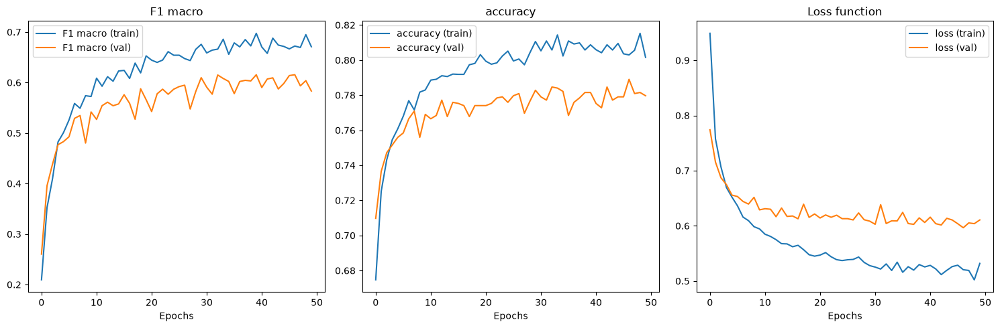

In [16]:
history_plot(history)

####  4.1.2 Macierz pomyłek

In [41]:
cmatrix, display = build_confusion_matrix(base_model, val)

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step


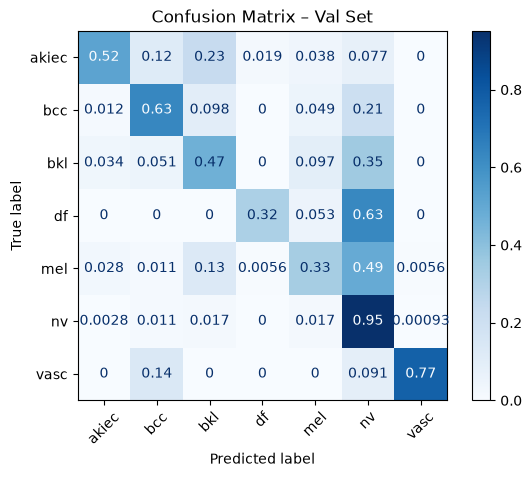

In [42]:
display.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix – Val Set")
plt.show()

### 4.2. Wersja A1 - lekka augmentacja

In [5]:
callbacks = [earlyStop,
    tf.keras.callbacks.ModelCheckpoint(
        filepath="../models/best_baseline_a1.keras",
        monitor="val_f1_macro",
        mode="max",
        save_best_only=True
    ),
]

#### 4.2.1. Definicja augmentacji i wizualizacja zaugmentowanych danych

In [20]:
def augmentation():
    return tf.keras.Sequential([
        layers.RandomFlip(),
        layers.RandomRotation(10/360, fill_mode='reflect'),
        layers.RandomZoom(0.05)
    ])

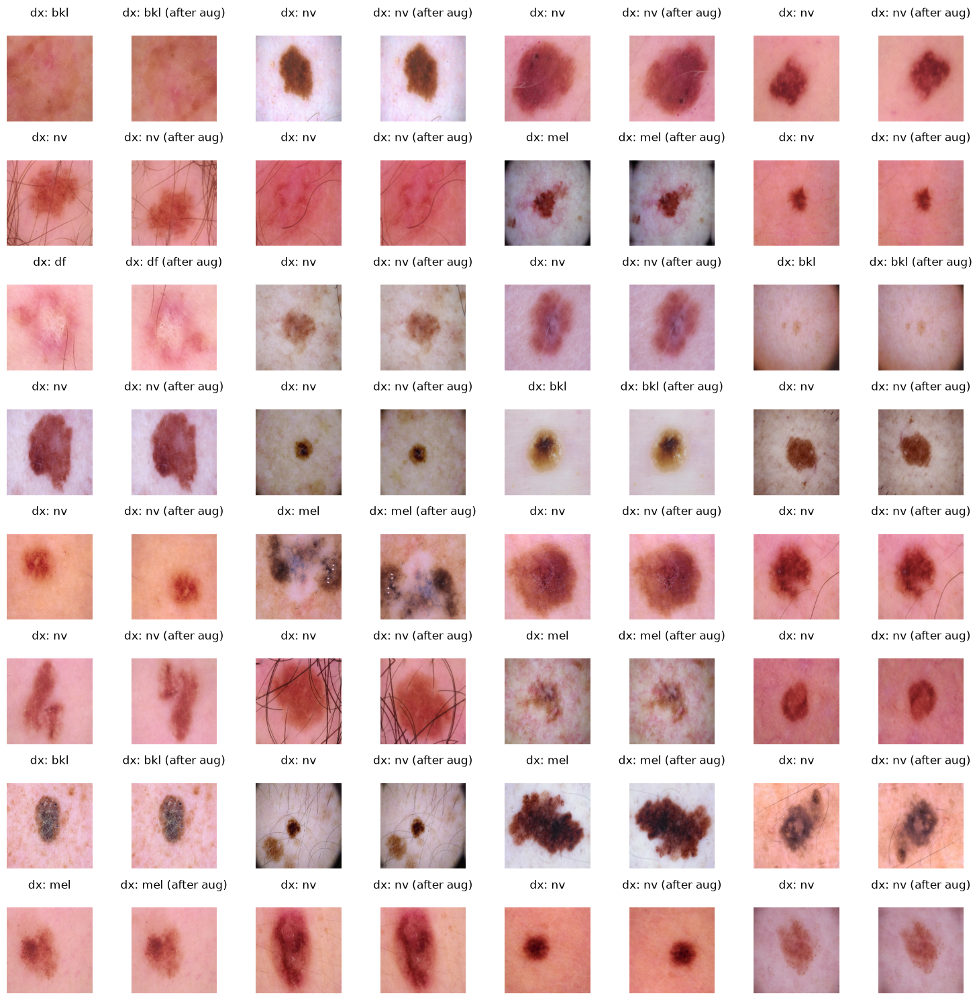

In [21]:
test_aug(augmentation)

#### 4.2.2. Budowa i trening modelu

In [22]:
baseline_model_a1 = build_base_model(augmentation)

In [23]:
baseline_model_a1.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=['accuracy', tf.keras.metrics.F1Score(average='macro', name='f1_macro')]
)

In [24]:
history_a1 = baseline_model_a1.fit(
    train,
    validation_data=val,
    epochs=50,
    callbacks=callbacks
)

Epoch 1/50


/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


201/201 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.6775 - f1_macro: 0.1999 - loss: 0.9512 - val_accuracy: 0.6985 - val_f1_macro: 0.2107 - val_loss: 0.7989
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - accuracy: 0.7112 - f1_macro: 0.3022 - loss: 0.7845 - val_accuracy: 0.7353 - val_f1_macro: 0.3747 - val_loss: 0.7358
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.7344 - f1_macro: 0.3948 - loss: 0.7305 - val_accuracy: 0.7366 - val_f1_macro: 0.3540 - val_loss: 0.7244
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - accuracy: 0.7419 - f1_macro: 0.4188 - loss: 0.7090 - val_accuracy: 0.7278 - val_f1_macro: 0.3867 - val_loss: 0.7078
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - accuracy: 0.7493 - f1_macro: 0.4580 - loss: 0.6857 - val_accuracy: 0.7434 - val_f1_macro: 0.4219 - val_loss: 0.6988
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.7571 - f1_macro: 0.4908 - loss: 0.6699 - val_accuracy: 0.7341 - val_f1_macro: 0.3855 - v

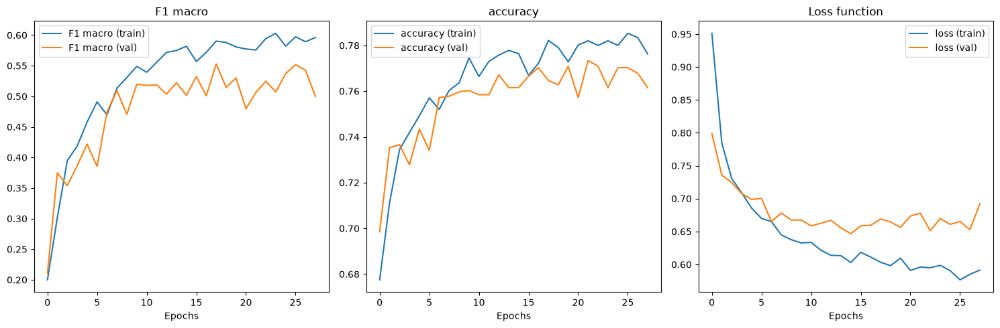

In [25]:
history_plot(history_a1)

#### 4.2.3. Macierz pomyłek

In [39]:
cmatrix_a1, display_a1 = build_confusion_matrix(baseline_model_a1, val)

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


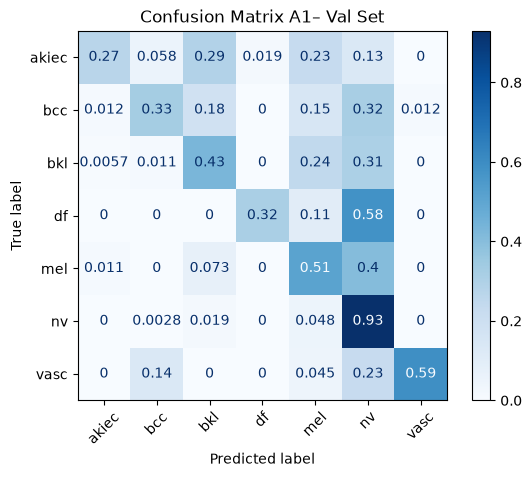

In [40]:
display_a1.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix A1– Val Set")
plt.show()

### 4.3. Wersja A2 - mocniejsza augmentacja

In [6]:
callbacks = [earlyStop,
    tf.keras.callbacks.ModelCheckpoint(
        filepath="../models/best_baseline_a2.keras",
        monitor="val_f1_macro",
        mode="max",
        save_best_only=True
    ),
]

#### 4.3.1. Definicja augmentacji

In [29]:
def heavy_augumentation():
    return tf.keras.Sequential([
        layers.RandomFlip(),
        layers.RandomRotation(25/360, fill_mode='reflect'),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10)
    ])

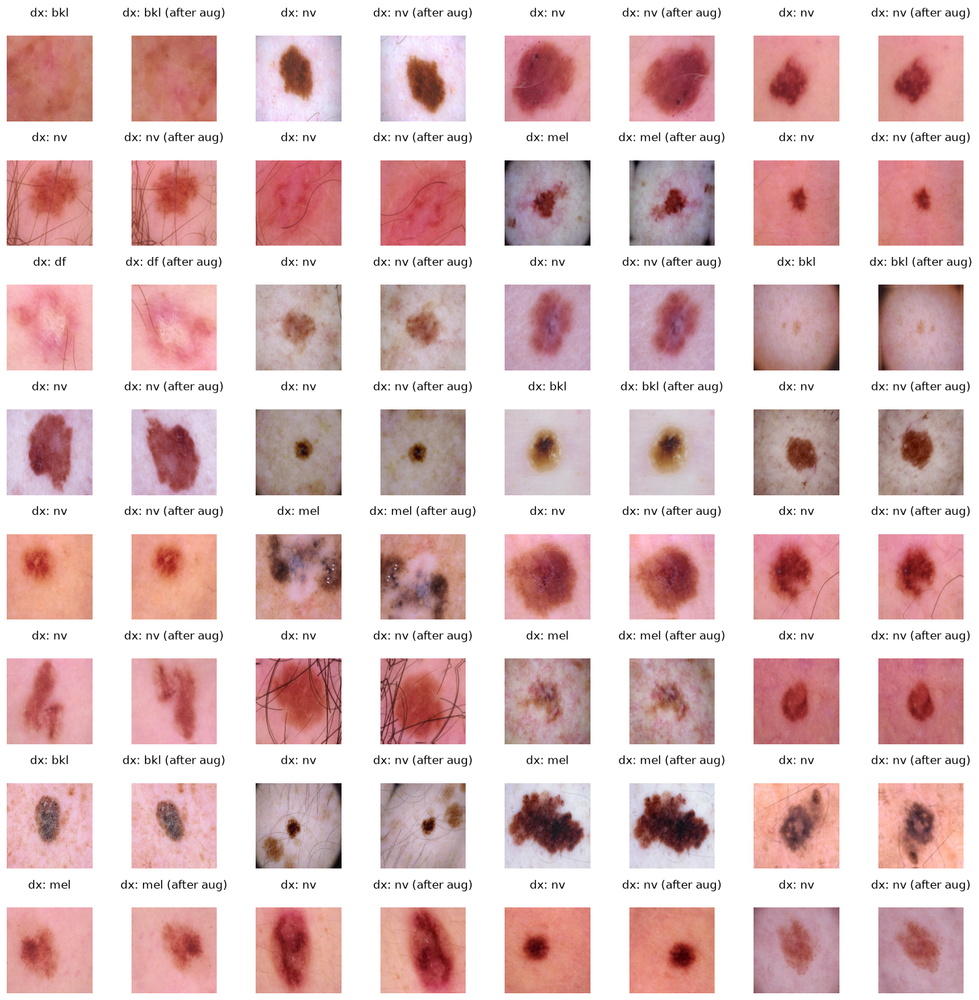

In [30]:
test_aug(heavy_augumentation)

#### 4.3.2. Budowa i trening modelu

In [31]:
baseline_model_a2 = build_base_model(heavy_augumentation)

In [32]:
baseline_model_a2.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=[ 'accuracy', tf.keras.metrics.F1Score(average='macro', name='f1_macro')]
)

In [33]:
history_a2 = baseline_model_a2.fit(
    train,
    validation_data=val,
    epochs=50,
    callbacks=callbacks)

Epoch 1/50


/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


201/201 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.6706 - f1_macro: 0.1976 - loss: 0.9561 - val_accuracy: 0.6991 - val_f1_macro: 0.2083 - val_loss: 0.8265
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - accuracy: 0.7085 - f1_macro: 0.2985 - loss: 0.7927 - val_accuracy: 0.7091 - val_f1_macro: 0.3002 - val_loss: 0.7714
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - accuracy: 0.7212 - f1_macro: 0.3591 - loss: 0.7447 - val_accuracy: 0.7360 - val_f1_macro: 0.3638 - val_loss: 0.7277
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - accuracy: 0.7397 - f1_macro: 0.4136 - loss: 0.7104 - val_accuracy: 0.7341 - val_f1_macro: 0.3887 - val_loss: 0.7270
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 8s 39ms/step - accuracy: 0.7447 - f1_macro: 0.4448 - loss: 0.6922 - val_accuracy: 0.7466 - val_f1_macro: 0.4326 - val_loss: 0.7111
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.7491 - f1_macro: 0.4802 - loss: 0.6864 - val_accuracy: 0.7409 - val_f1_macro: 0.4107 - v

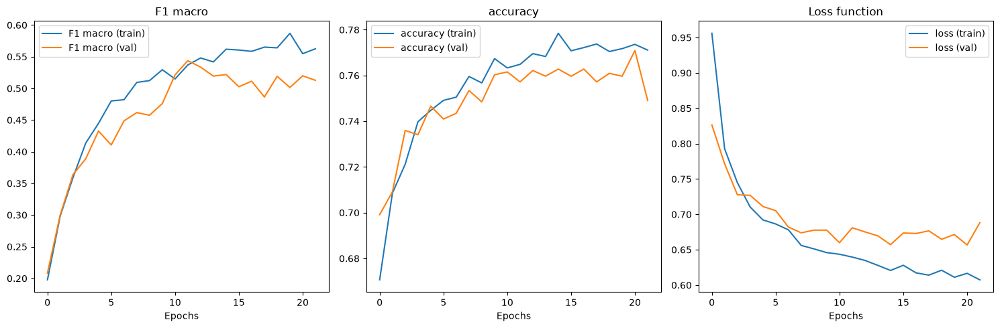

In [34]:
history_plot(history_a2)

#### 4.3.3. Macierz pomyłek

In [44]:
cmatrix_a2, display_a2 = build_confusion_matrix(baseline_model_a2, val)

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


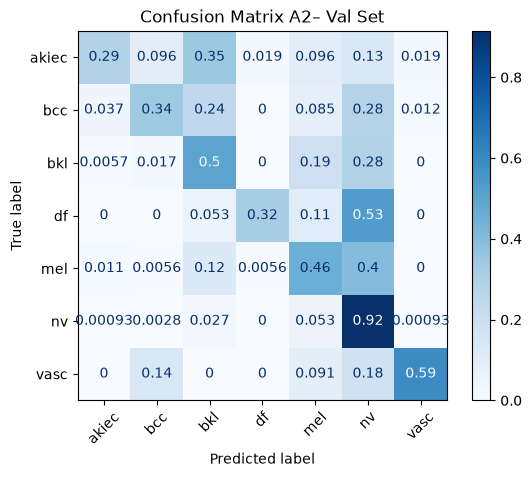

In [45]:
display_a2.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix A2– Val Set")
plt.show()

## ***5. Analiza wyników i wybór baseline'u***

In [59]:
loss_a0, acc_a0, f1_macro_a0 = base_model.evaluate(val)
loss_a1, acc_a1, f1_macro_a1 = baseline_model_a1.evaluate(val)
loss_a2, acc_a2, f1_macro_a2 = baseline_model_a2.evaluate(val)

print(f"F1 macro:\n dla A0: {f1_macro_a0}\n dla A1: {f1_macro_a1}\n dla A2: {f1_macro_a2}")

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.7890 - f1_macro: 0.6154 - loss: 0.5965
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7647 - f1_macro: 0.5529 - loss: 0.6690
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7572 - f1_macro: 0.5438 - loss: 0.6810
F1 macro:
 dla A0: 0.615447461605072
 dla A1: 0.5529234409332275
 dla A2: 0.5437918305397034


In [60]:
cm1_0 = cmatrix_a1-cmatrix
cm2_0 = cmatrix_a2-cmatrix

display1_0 = ConfusionMatrixDisplay(cm1_0, display_labels=class_names)
display2_0 = ConfusionMatrixDisplay(cm2_0, display_labels=class_names)

Text(0.5, 1.0, 'Difference between high and no augmentation')

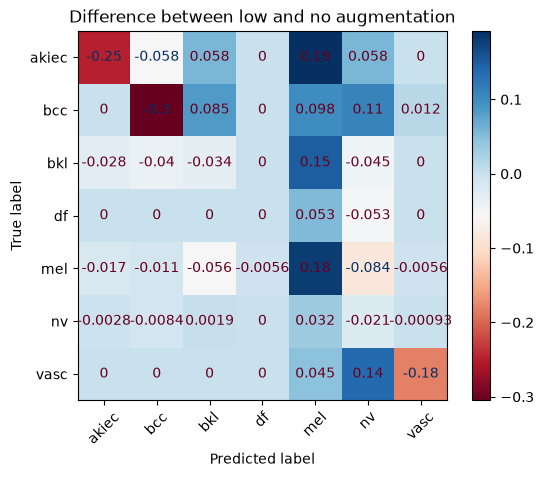

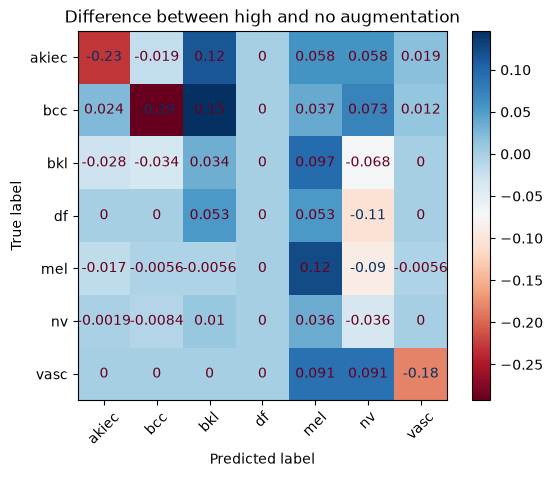

In [64]:
display1_0.plot(cmap='RdBu',xticks_rotation=45)
plt.title("Difference between low and no augmentation")

display2_0.plot(cmap='RdBu', xticks_rotation=45)
plt.title("Difference between high and no augmentation")

***Wnioski***: Trening samej głowicy klasyfikującej modelu (bez stosowania harmonogramu LR) pozwolił osiągnąć wynik $F1_{macro}=0.61$ dla modelu bez augmentacji danych. Był to najwyższy wynik dla przebadanych wariantów modelu. 

Zauważono tendencje modeli do przypisywania błędnie klasyfikowanych przykładów do klas o większej liczebności. Można to interpretować jako wynik niezbalansowania klas (*class imbalance bias*). Po analizie różnicy macierzy pomyłek zauważono także, że Wraz ze wzrostem augmentacji model częściej przypisuje próbki do klas zgodnie z ich częstością występowania w zbiorze treningowym, co może sugerować zwiększony wpływ niezbalansowania klas na decyzje modelu. Zrezygnowano więc z modeli korzystających z augmentacji, jako że może to oznaczać to niewielkie wykorzystanie przez model informacji pozwalających odróżniać poszczególne klasy.

Wobec tego, pierwszym punktem odniesienia będzie wariant modelu A0.

W następnych krokach zostanie zbadany wpływ następujących elementów na wyniki modelu:
- zakresów odmrażania ciała modelu do fine-tuningu
- augmentacji danych
- class weights
- harmonogram LR
- usuwanie artefaktów